# Mumbai Rainfall Forecasting

## Project Objective

The objective of this project is to develop a machine learning/time-series forecasting model to predict rainfall for upcoming months using historical monthly rainfall data for Mumbai.

The dataset contains annual rainfall records from 1901 to 2021, with rainfall values provided separately for each month and an annual total.

The project will investigate historical rainfall trends and seasonality before developing and evaluating forecasting models.

## Approach Overview

The project follows a time-series forecasting workflow:

1. Inspect and validate the dataset
2. Reshape the data into a monthly time series
3. Explore rainfall patterns, seasonality, and temporal dependence
4. Create lag and rolling-window features
5. Train and evaluate multiple machine learning models
6. Validate the selected model using time-series cross-validation
7. Tune the Random Forest hyperparameters
8. Compare machine learning models against a seasonal baseline
9. Select the final forecasting approach
10. Retrain the final model using the available historical data
11. Generate monthly rainfall forecasts

## Data Loading & Initial Inspection

In [24]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns

In [25]:
df = pd.read_csv('mumbai-monthly-rains.csv')
df.head()

,Year,Jan,Feb,Mar,April,May,June,July,Aug,Sept,Oct,Nov,Dec,Total
0,1901,13.116602,0.000000,0.000000,3.949669,17.139791,640.714036,888.369692,545.045796,64.271513,9.871696,0.000000,0.000000,2182.478796
1,1902,0.000000,0.000000,0.000000,0.000000,0.355001,247.998782,408.433730,566.595863,688.913455,28.654092,0.488864,19.526547,1960.966334
2,1903,0.000000,0.000000,0.844034,0.000000,220.568740,370.849048,902.447896,602.420828,264.589816,157.892877,0.000000,0.000000,2519.613240
3,1904,0.000000,0.000000,11.381769,0.000000,0.000000,723.081969,390.886799,191.581927,85.704754,38.679948,0.000000,0.000000,1441.317168
4,1905,0.662561,1.713452,0.000000,0.000000,0.000000,123.870892,581.827975,167.382149,172.297723,7.365924,24.903575,0.000000,1080.024250


## Data Loading

The dataset contains historical monthly rainfall observations for Mumbai from 1901 to 2021.

The initial inspection is performed to understand the dataset structure, data types, dimensions, summary statistics, and presence of missing values before beginning the forecasting analysis.

In [26]:
df.shape

(121, 14)

In [27]:
df.describe()

,Year,Jan,Feb,Mar,April,May,June,July,Aug,Sept,Oct,Nov,Dec,Total
count,121.000000,121.000000,121.000000,121.000000,121.000000,121.000000,121.000000,121.000000,121.000000,121.000000,121.000000,121.000000,121.000000,121.000000
mean,1961.000000,1.567235,0.929358,0.869231,1.428458,18.183632,517.854402,757.407412,465.600818,312.885747,73.983526,13.849462,3.556428,2168.115709
std,35.073732,6.462247,3.077050,2.890032,7.371307,48.628812,251.067016,285.836188,249.072915,205.135368,96.686113,29.689941,12.342390,533.263926
min,1901.000000,0.000000,0.000000,0.000000,0.000000,0.000000,61.058662,103.209194,87.493370,36.313545,0.000000,0.000000,0.000000,1058.840525
25%,1931.000000,0.000000,0.000000,0.000000,0.000000,0.000000,324.094617,540.745923,268.002392,149.584208,9.871696,0.000000,0.000000,1834.996957
50%,1961.000000,0.000000,0.000000,0.000000,0.000000,0.355001,482.449872,788.403637,445.870342,269.276549,43.479170,1.066086,0.000000,2126.054987
75%,1991.000000,0.000000,0.152298,0.000000,0.194165,4.208322,678.040770,942.616099,604.372615,398.645218,98.235161,9.373154,0.176149,2478.558089
max,2021.000000,51.348290,21.107118,18.252996,75.541818,234.392757,1219.518576,1358.833554,1200.956558,987.796660,552.902707,164.348387,90.044602,3563.259531


In [28]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 121 entries, 0 to 120
Data columns (total 14 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Year    121 non-null    int64  
 1   Jan     121 non-null    float64
 2   Feb     121 non-null    float64
 3   Mar     121 non-null    float64
 4   April   121 non-null    float64
 5   May     121 non-null    float64
 6   June    121 non-null    float64
 7   July    121 non-null    float64
 8   Aug     121 non-null    float64
 9   Sept    121 non-null    float64
 10  Oct     121 non-null    float64
 11  Nov     121 non-null    float64
 12  Dec     121 non-null    float64
 13  Total   121 non-null    float64
dtypes: float64(13), int64(1)
memory usage: 13.4 KB


In [29]:
df.isna().sum()

Year     0
Jan      0
Feb      0
Mar      0
April    0
May      0
June     0
July     0
Aug      0
Sept     0
Oct      0
Nov      0
Dec      0
Total    0
dtype: int64

### Initial Data Quality Check

The dataset was inspected for its dimensions, data types, descriptive statistics, and missing values. This initial check helps ensure that the data is suitable for further time-series preprocessing and analysis.

## Data Validation

### Validating the Annual Total

The dataset contains both individual monthly rainfall values and an annual `Total` column. Before proceeding, the annual total is independently calculated by summing the twelve monthly rainfall values.

The calculated total is then compared with the provided `Total` column to verify that the two represent the same annual rainfall quantity.

In [30]:
months = ['Jan' , 'Feb' ,'Mar',	'April','May',	'June',	'July',	'Aug',	'Sept',	'Oct',	'Nov',	'Dec']

df['calculated_total'] = df[months].sum(axis=1)

df[['Year' , 'Total' , 'calculated_total']].head(20)

,Year,Total,calculated_total
0,1901,2182.478796,2182.478796
1,1902,1960.966334,1960.966334
2,1903,2519.613240,2519.613240
3,1904,1441.317168,1441.317168
4,1905,1080.024250,1080.024250
5,1906,1777.372453,1777.372453
6,1907,2518.414598,2518.414598
7,1908,1916.604932,1916.604932
8,1909,2477.007007,2477.007007
9,1910,1883.825290,1883.825290


In [31]:
difference = df['Total'] - df['calculated_total']
print('Differences Statistics : \n',difference.describe(),'\n')
print('Differences : \n',difference)

Differences Statistics : 
 count    1.210000e+02
mean     5.041308e-09
std      2.763283e-07
min     -4.839999e-07
25%     -2.330000e-07
50%      4.700019e-08
75%      2.230001e-07
max      4.990002e-07
dtype: float64 

Differences : 
 0      2.299976e-08
1      8.200027e-08
2      2.259999e-07
3      3.500004e-07
4     -2.220002e-07
           ...     
116    2.229999e-07
117    4.070002e-07
118   -1.839999e-07
119   -1.210001e-07
120   -2.160000e-07
Length: 121, dtype: float64


In [32]:
np.allclose(df['Total'], df['calculated_total'])

True

### Validation Result

The independently calculated annual totals were compared with the provided `Total` values. `np.allclose()` returned `True`, indicating that the differences are negligible within the numerical tolerance.

Therefore, the calculated validation column is no longer required and is removed from the dataset.

In [33]:
df.drop(columns='calculated_total', inplace = True)
df

,Year,Jan,Feb,Mar,April,May,June,July,Aug,Sept,Oct,Nov,Dec,Total
0,1901,13.116602,0.000000,0.000000,3.949669,17.139791,640.714036,888.369692,545.045796,64.271513,9.871696,0.000000,0.000000,2182.478796
1,1902,0.000000,0.000000,0.000000,0.000000,0.355001,247.998782,408.433730,566.595863,688.913455,28.654092,0.488864,19.526547,1960.966334
2,1903,0.000000,0.000000,0.844034,0.000000,220.568740,370.849048,902.447896,602.420828,264.589816,157.892877,0.000000,0.000000,2519.613240
3,1904,0.000000,0.000000,11.381769,0.000000,0.000000,723.081969,390.886799,191.581927,85.704754,38.679948,0.000000,0.000000,1441.317168
4,1905,0.662561,1.713452,0.000000,0.000000,0.000000,123.870892,581.827975,167.382149,172.297723,7.365924,24.903575,0.000000,1080.024250
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
116,2017,0.000000,0.000000,0.000000,0.000000,1.043890,584.946748,702.386594,796.997046,539.932782,102.108135,0.000000,79.685446,2807.100642
117,2018,0.000000,0.000000,0.000000,0.000000,0.000000,846.855987,913.470461,228.590420,78.935944,13.354574,8.939212,0.000000,2090.146599
118,2019,0.000000,0.000000,0.000000,0.000000,0.000000,412.763730,1302.466441,479.834603,987.796660,92.008442,57.014501,1.172425,3333.056801
119,2020,0.000000,0.000000,0.104274,0.000000,0.000000,439.814569,1328.766631,1182.080688,411.247678,184.458385,0.000000,16.787305,3563.259531


## Data Reshaping

The original dataset stores each month as a separate column. For time-series analysis, it is more convenient to have one observation per month.

The dataset is therefore transformed from wide format to long format, where each row represents the rainfall recorded for one month in one year.

In [34]:
rainfall_long = df.melt(
    id_vars= 'Year',
    value_vars= months,
    var_name= 'Months',
    value_name= 'Rainfall'
)
rainfall_long

,Year,Months,Rainfall
0,1901,Jan,13.116602
1,1902,Jan,0.000000
2,1903,Jan,0.000000
3,1904,Jan,0.000000
4,1905,Jan,0.662561
...,...,...,...
1447,2017,Dec,79.685446
1448,2018,Dec,0.000000
1449,2019,Dec,1.172425
1450,2020,Dec,16.787305


### Creating a Numerical Month Representation

The month names are converted into numerical month values from 1 to 12. This provides a consistent numerical representation that can be used to construct a datetime index.

In [35]:
month_mapping = {month:i for i , month in enumerate(months , start= 1)}
month_mapping

{'Jan': 1,
 'Feb': 2,
 'Mar': 3,
 'April': 4,
 'May': 5,
 'June': 6,
 'July': 7,
 'Aug': 8,
 'Sept': 9,
 'Oct': 10,
 'Nov': 11,
 'Dec': 12}

In [36]:
rainfall_long['Month_Number'] = rainfall_long.Months.map(month_mapping)
rainfall_long

,Year,Months,Rainfall,Month_Number
0,1901,Jan,13.116602,1
1,1902,Jan,0.000000,1
2,1903,Jan,0.000000,1
3,1904,Jan,0.000000,1
4,1905,Jan,0.662561,1
...,...,...,...,...
1447,2017,Dec,79.685446,12
1448,2018,Dec,0.000000,12
1449,2019,Dec,1.172425,12
1450,2020,Dec,16.787305,12


In [37]:
date_data = {
    'year' : rainfall_long.Year,
    'month' : rainfall_long.Month_Number,
    'day' : 1
}

rainfall_long['Date'] = pd.to_datetime(date_data)
rainfall_long

,Year,Months,Rainfall,Month_Number,Date
0,1901,Jan,13.116602,1,1901-01-01
1,1902,Jan,0.000000,1,1902-01-01
2,1903,Jan,0.000000,1,1903-01-01
3,1904,Jan,0.000000,1,1904-01-01
4,1905,Jan,0.662561,1,1905-01-01
...,...,...,...,...,...
1447,2017,Dec,79.685446,12,2017-12-01
1448,2018,Dec,0.000000,12,2018-12-01
1449,2019,Dec,1.172425,12,2019-12-01
1450,2020,Dec,16.787305,12,2020-12-01


In [38]:
rainfall_long.sort_values(by = 'Date' , axis=0 , ascending=True, inplace= True)
rainfall_long


,Year,Months,Rainfall,Month_Number,Date
0,1901,Jan,13.116602,1,1901-01-01
121,1901,Feb,0.000000,2,1901-02-01
242,1901,Mar,0.000000,3,1901-03-01
363,1901,April,3.949669,4,1901-04-01
484,1901,May,17.139791,5,1901-05-01
...,...,...,...,...,...
967,2021,Aug,323.199896,8,2021-08-01
1088,2021,Sept,601.247517,9,2021-09-01
1209,2021,Oct,36.040432,10,2021-10-01
1330,2021,Nov,25.156942,11,2021-11-01


### Creating the Time Index

A `Date` column is created using the year and numerical month. The observations are then sorted chronologically and the date is set as the index.

Maintaining chronological order is essential because this is a time-series forecasting problem, where future observations must not be used to predict the past.



In [39]:
rainfall_long = rainfall_long.set_index('Date')
rainfall_long

,Year,Months,Rainfall,Month_Number
Date,,,,
1901-01-01,1901,Jan,13.116602,1
1901-02-01,1901,Feb,0.000000,2
1901-03-01,1901,Mar,0.000000,3
1901-04-01,1901,April,3.949669,4
1901-05-01,1901,May,17.139791,5
...,...,...,...,...
2021-08-01,2021,Aug,323.199896,8
2021-09-01,2021,Sept,601.247517,9
2021-10-01,2021,Oct,36.040432,10


### Time-Series Dataset

The data is now organized as a chronological monthly time series and is ready for exploratory analysis.

## EDA

### Monthly Rainfall Over time

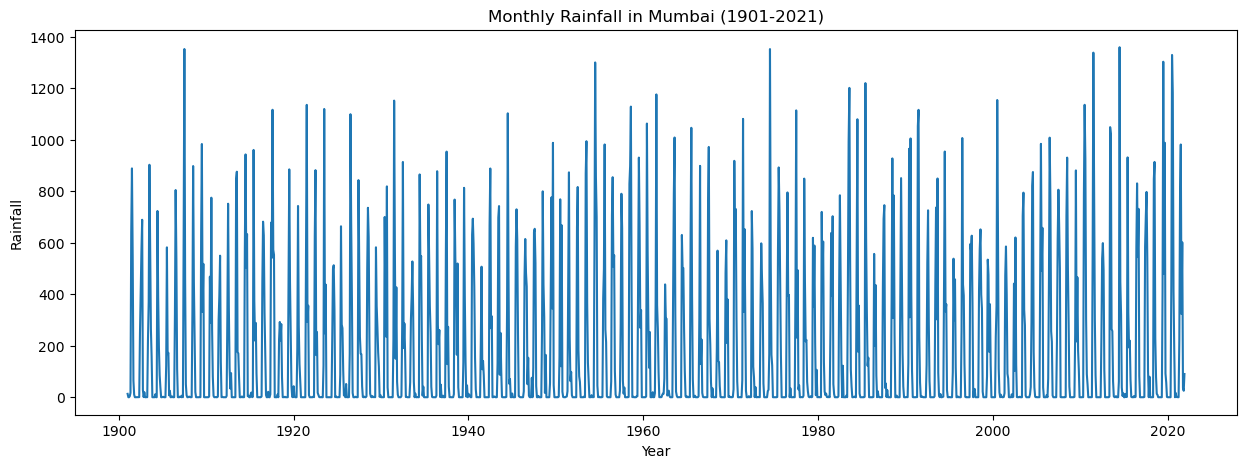

In [40]:
plt.figure(figsize= (15,5))

plt.plot(
    rainfall_long.index,
    rainfall_long.Rainfall
)

plt.xlabel('Year')
plt.ylabel('Rainfall')
plt.title('Monthly Rainfall in Mumbai (1901-2021)')
plt.savefig("graphs/rainfall_over_time.png", dpi=300, bbox_inches="tight")
plt.show()

### Observation
#### The monthly rainfall series exhibits strong seasonality with substantial month-to-month variability and occasional extreme rainfall events. No clear long-term trend is visually apparent. Therefore, seasonal patterns are likely to be an important component of the forecasting model.

### Monthly Seasonality

In [41]:
monthly_average = rainfall_long.groupby('Months')['Rainfall'].mean().reindex(months)
monthly_average

Months
Jan        1.567235
Feb        0.929358
Mar        0.869231
April      1.428458
May       18.183632
June     517.854402
July     757.407412
Aug      465.600818
Sept     312.885747
Oct       73.983526
Nov       13.849462
Dec        3.556428
Name: Rainfall, dtype: float64

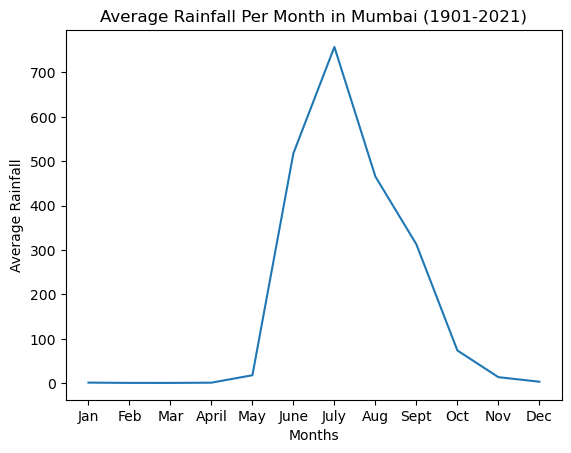

In [42]:
plt.plot(
    rainfall_long.Months.unique(),
    monthly_average
)
plt.xlabel('Months')
plt.ylabel('Average Rainfall')
plt.title('Average Rainfall Per Month in Mumbai (1901-2021)')
plt.savefig("graphs/monthly_rainfall_seasonality.png", dpi=300, bbox_inches="tight")
plt.show()

### Observation
#### July has the highest average rainfall, followed by june, while March to May have very low average rainfall. There is a substantial difference between the wettest and driest months, indicating a strong and consistent seasonal pattern in monthly rainfall.

### Rainfall variability across year within each month

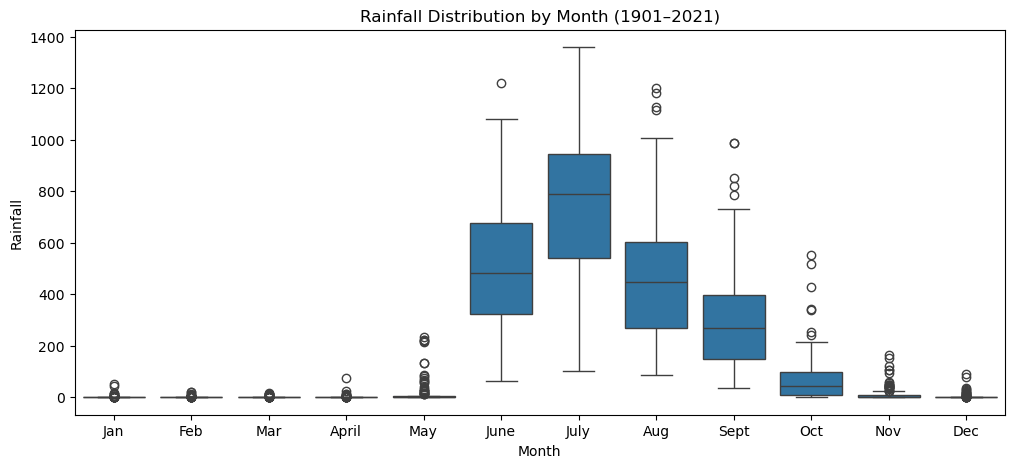

In [43]:
plt.figure(figsize=(12, 5))

sns.boxplot(
    data=rainfall_long,
    x='Months',
    y='Rainfall'
)

plt.xlabel('Month')
plt.ylabel('Rainfall')
plt.title('Rainfall Distribution by Month (1901–2021)')
plt.savefig("graphs/monthly_rainfall_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

In [44]:
monthly_std = rainfall_long.groupby('Months')['Rainfall'].std()
monthly_std.sort_values(ascending=True)

Months
Mar        2.890032
Feb        3.077050
Jan        6.462247
April      7.371307
Dec       12.342390
Nov       29.689941
May       48.628812
Oct       96.686113
Sept     205.135368
Aug      249.072915
June     251.067016
July     285.836188
Name: Rainfall, dtype: float64

### Observation
#### The boxplot and standard deviation show that rainfall variability is much higher during the monsoon months, particularly June–September, with July showing the highest variation. In contrast, January–April have very low variability. This indicates that rainfall during the wetter months is more unpredictable and may be more challenging for the forecasting model to predict accurately.

### Time Dependence and auto correlation

In [45]:
for lag in [1, 2, 3, 6, 12]:
    print(f'Lag {lag}: {rainfall_long["Rainfall"].autocorr(lag=lag):.3f}')

Lag 1: 0.523
Lag 2: 0.144
Lag 3: -0.157
Lag 6: -0.372
Lag 12: 0.748


### Observation
#### The autocorrelation analysis shows a moderate positive relationship at lag 1 (0.523), while lag 12 has a strong positive correlation of 0.748. The high lag-12 autocorrelation indicates that rainfall in a given month is strongly related to rainfall in the same month of the previous year, confirming the presence of strong yearly seasonality. The results suggest that lag-based features, particularly the 12-month lag, may be useful for rainfall forecasting.

## EDA Summary

The exploratory analysis reveals three important characteristics of the rainfall series:

- Rainfall exhibits strong yearly seasonality, with substantially higher rainfall during the monsoon months.
- Rainfall variability is considerably higher during the wet months than during the dry months.
- The autocorrelation at lag 12 is strong, indicating that rainfall in a given month is related to rainfall in the same month of the previous year.

These observations provide the motivation for creating lag-based and rolling-window features for the machine learning models.

## Feature Engineering

### Lag Features

The autocorrelation analysis showed meaningful temporal dependence, particularly at lag 12.

Lag features are therefore created to provide the model with information from previous observations:

- `Rainfall_lag_1`: rainfall from the previous month
- `Rainfall_lag_12`: rainfall from the same month in the previous year

In [46]:
rainfall_long['Rainfall_lag_1'] = rainfall_long['Rainfall'].shift(1)
rainfall_long['Rainfall_lag_12'] = rainfall_long['Rainfall'].shift(12)

rainfall_long[['Rainfall','Rainfall_lag_1','Rainfall_lag_12']].head(24)

,Rainfall,Rainfall_lag_1,Rainfall_lag_12
Date,,,
1901-01-01,13.116602,NaN,NaN
1901-02-01,0.000000,13.116602,NaN
1901-03-01,0.000000,0.000000,NaN
1901-04-01,3.949669,0.000000,NaN
1901-05-01,17.139791,3.949669,NaN
1901-06-01,640.714036,17.139791,NaN
1901-07-01,888.369692,640.714036,NaN
1901-08-01,545.045796,888.369692,NaN
1901-09-01,64.271513,545.045796,NaN


### Rolling-Window Features

Rolling averages are created to represent recent rainfall patterns while using only previous observations.

The rolling windows are shifted by one month before calculating the mean so that the current month's rainfall is not included in its own feature value.

The following windows are tested:

- Rolling 2 → recent short-term pattern
- Rolling 3 → short-term pattern
- Rolling 6 → medium-term pattern
- Rolling 12 → longer-term pattern

In [47]:
rainfall_long['Rainfall_rolling_2'] = rainfall_long['Rainfall'].shift(1).rolling(2).mean()
rainfall_long['Rainfall_rolling_3'] = rainfall_long['Rainfall'].shift(1).rolling(3).mean()
rainfall_long['Rainfall_rolling_6'] = rainfall_long['Rainfall'].shift(1).rolling(6).mean()
rainfall_long['Rainfall_rolling_12'] = rainfall_long['Rainfall'].shift(1).rolling(12).mean()

rainfall_long[['Rainfall',
               'Rainfall_lag_1',
               'Rainfall_lag_12',
               'Rainfall_rolling_2',
               'Rainfall_rolling_3',
               'Rainfall_rolling_6',
               'Rainfall_rolling_12']].head(24)

,Rainfall,Rainfall_lag_1,Rainfall_lag_12,Rainfall_rolling_2,Rainfall_rolling_3,Rainfall_rolling_6,Rainfall_rolling_12
Date,,,,,,,
1901-01-01,13.116602,NaN,NaN,NaN,NaN,NaN,NaN
1901-02-01,0.000000,13.116602,NaN,NaN,NaN,NaN,NaN
1901-03-01,0.000000,0.000000,NaN,6.558301,NaN,NaN,NaN
1901-04-01,3.949669,0.000000,NaN,0.000000,4.372201,NaN,NaN
1901-05-01,17.139791,3.949669,NaN,1.974835,1.316556,NaN,NaN
1901-06-01,640.714036,17.139791,NaN,10.544730,7.029820,NaN,NaN
1901-07-01,888.369692,640.714036,NaN,328.926914,220.601166,112.486683,NaN
1901-08-01,545.045796,888.369692,NaN,764.541864,515.407840,258.362198,NaN
1901-09-01,64.271513,545.045796,NaN,716.707744,691.376508,349.203164,NaN


In [48]:
rainfall_model = rainfall_long.dropna().copy()

## Train-Test Split

Because this is a time-series problem, the data is split chronologically rather than randomly.

The first 80% of observations are used for training and the remaining 20% are held out as the test set.

This ensures that the model is trained only on observations that occurred before the test period, allowing the test set to represent future-like unseen observations.

In [49]:
split = int(len(rainfall_model) * 0.8)

train = rainfall_model.iloc[:split]
test = rainfall_model.iloc[split:]

print("Train:", train.index.min(), "to", train.index.max())
print("Test :", test.index.min(), "to", test.index.max())

Train: 1902-01-01 00:00:00 to 1997-12-01 00:00:00
Test : 1998-01-01 00:00:00 to 2021-12-01 00:00:00


## Baseline Model
### Linear Regression Baseline

Linear Regression is used as the initial machine learning baseline.

The baseline uses the initial feature set:

- `Month_Number`
- `Rainfall_lag_1`
- `Rainfall_lag_12`

This provides a simple reference point against which more complex models and additional features can be evaluated.

In [50]:
features = [
    'Month_Number',
    'Rainfall_lag_1',
    'Rainfall_lag_12'
]

X = rainfall_model[features]
y = rainfall_model['Rainfall']

In [51]:
X_train = train[features]
y_train = train['Rainfall']

X_test = test[features]
y_test = test['Rainfall']

In [52]:
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(1152, 3)
(288, 3)
(1152,)
(288,)


In [53]:
from sklearn.linear_model import LinearRegression

baseline_model = LinearRegression()

baseline_model.fit(X_train,y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [54]:
y_pred = baseline_model.predict(X_test)
y_pred[:10]

array([ 36.96789361,  30.50272834,  29.96674685,  29.59926243,
        28.89478387, 418.74903167, 477.80407   , 544.02723019,
       385.20689618,  98.87267899])

In [55]:
from sklearn.metrics import mean_absolute_error, mean_squared_error ,r2_score

mae = mean_absolute_error(y_test, y_pred)

rmse = np.sqrt(mean_squared_error(y_test, y_pred))

r2 = r2_score(y_test , y_pred)

print("MAE:", mae)
print("RMSE:", rmse)
print("R2score", r2)

MAE: 122.57526524461352
RMSE: 207.88286079269227
R2score 0.5904362681311497


### Baseline Result

The Linear Regression model provides a reference performance level for subsequent feature engineering and model comparisons.

## Rolling feature experiment

In [56]:
# Rolling Feature Experiment
# Testing each rolling window individually, added to the baseline features
# (Month_Number, Rainfall_lag_1, Rainfall_lag_12)

rolling_windows = {
    'Rolling 2': 'Rainfall_rolling_2',
    'Rolling 3': 'Rainfall_rolling_3',
    'Rolling 6': 'Rainfall_rolling_6',
    'Rolling 12': 'Rainfall_rolling_12'
}

base_features = ['Month_Number', 'Rainfall_lag_1', 'Rainfall_lag_12']
rolling_results = []

for label, col in rolling_windows.items():
    feats = base_features + [col]
    X_train_r = train[feats]
    X_test_r = test[feats]

    model = LinearRegression()
    model.fit(X_train_r, y_train)
    y_pred_r = model.predict(X_test_r)

    rolling_results.append({
        'Feature Set': label,
        'MAE': mean_absolute_error(y_test, y_pred_r),
        'RMSE': np.sqrt(mean_squared_error(y_test, y_pred_r)),
        'R²': r2_score(y_test, y_pred_r)
    })

# Also test Rolling 3 + Rolling 6 combined
feats_combo = base_features + ['Rainfall_rolling_3', 'Rainfall_rolling_6']
model_combo = LinearRegression()
model_combo.fit(train[feats_combo], y_train)
y_pred_combo = model_combo.predict(test[feats_combo])

rolling_results.append({
    'Feature Set': 'Rolling 3 + Rolling 6',
    'MAE': mean_absolute_error(y_test, y_pred_combo),
    'RMSE': np.sqrt(mean_squared_error(y_test, y_pred_combo)),
    'R²': r2_score(y_test, y_pred_combo)
})

# Baseline for comparison
baseline_row = {
    'Feature Set': 'Baseline (no rolling)',
    'MAE': mae, 'RMSE': rmse, 'R²': r2
}

rolling_results_df = pd.DataFrame([baseline_row] + rolling_results)
rolling_results_df

,Feature Set,MAE,RMSE,R²
0,Baseline (no rolling),122.575265,207.882861,0.590436
1,Rolling 2,122.021702,206.208895,0.597006
2,Rolling 3,119.626556,203.940262,0.605824
3,Rolling 6,124.832829,201.533445,0.615073
4,Rolling 12,122.886237,207.062081,0.593664
5,Rolling 3 + Rolling 6,123.722965,201.108059,0.616696


### Rolling Feature Experiment — Observation

Rolling features were evaluated individually by adding them to the baseline features (Month_Number, Rainfall_lag_1 and Rainfall_lag_12).

Rolling 3 produced the lowest MAE (119.63), indicating the lowest average absolute prediction error.

Rolling 6 produced the lowest RMSE (201.53) and highest R² (0.6151), indicating better performance in explaining overall variation and reducing the influence of large prediction errors.

Rolling 2 provided only a small improvement over the baseline, while Rolling 12 showed little improvement.


Combining Rolling 3 and Rolling 6 produced a slight improvement over the individual Rolling 6 feature, reducing RMSE from 201.53 to 201.11 and increasing R² from 0.6151 to 0.6167. However, Rolling 3 alone still achieved the lowest MAE of 119.63.

This indicates that shorter-term and medium-term rainfall patterns provide complementary information, although the improvement from combining them is relatively small. The final feature set will be determined after comparing different forecasting models.

### Decision

The rolling features provide only limited improvement over the baseline. Their usefulness will therefore be evaluated further when comparing different machine learning models rather than assuming that adding more features will necessarily improve forecasting performance.

## Model Comparison

The feature set developed from the exploratory analysis and rolling-feature experiments is now used to compare different machine learning algorithms.

The objective is to determine whether nonlinear models can improve upon the Linear Regression baseline.

### Random Forest

In [57]:
features_final_candidate = [
    'Month_Number',
    'Rainfall_lag_1',
    'Rainfall_lag_12',
    'Rainfall_rolling_3',
    'Rainfall_rolling_6'
]

X_train_final = train[features_final_candidate]
X_test_final = test[features_final_candidate]

y_train_final = train['Rainfall']
y_test_final = test['Rainfall']

In [58]:
from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor(
     n_estimators=300,
    random_state=42,
    n_jobs=-1
)

rf.fit(X_train_final,y_train_final)


,n_estimators,300
,criterion,'squared_error'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [59]:
y_pred_rf = rf.predict(X_test_final)

In [60]:
mae_rf = mean_absolute_error(y_test_final, y_pred_rf)

rmse_rf = np.sqrt(
    mean_squared_error(y_test_final, y_pred_rf)
)

r2_rf = r2_score(
    y_test_final,
    y_pred_rf
)

print("MAE:", mae_rf)
print("RMSE:", rmse_rf)
print("R²:", r2_rf)

MAE: 95.3282077361444
RMSE: 178.52320795044253
R²: 0.6979537233532083


### XGboost

In [61]:
from xgboost import XGBRegressor

xgb = XGBRegressor(
     n_estimators=300,
    learning_rate=0.05,
    max_depth=5,
    random_state=42
)

xgb.fit(X_train_final,y_train_final)

y_pred_xgb = xgb.predict(X_test_final)

mae_xgb = mean_absolute_error(y_test_final, y_pred_xgb)

rmse_xgb = np.sqrt(
    mean_squared_error(y_test_final, y_pred_xgb)
)

r2_xgb = r2_score(
    y_test_final,
    y_pred_xgb
)

print("MAE:", mae_xgb)
print("RMSE:", rmse_xgb)
print("R²:", r2_xgb)


MAE: 95.66598524547527
RMSE: 179.30612529149155
R²: 0.6952986533647065


| Model             |     MAE ↓ |     RMSE ↓ |       R² ↑ |
| ----------------- | --------: | ---------: | ---------: |
| Linear Regression |    123.73 |     201.11 |     0.6167 |
| **Random Forest** | **95.33** | **178.52** | **0.6980** |
| XGBoost           |     95.67 |     179.31 |     0.6953 |

Compared with XGBoost:

MAE: 95.33 < 95.67 → RF wins
RMSE: 178.52 < 179.31 → RF wins
R²: 0.6980 > 0.6953 → RF wins

So right now:

🏆 Random Forest is our best model.(pending baseline validation later in this notebook)

### Model Comparison — Observation

Random Forest performs slightly better than XGBoost across all three evaluation metrics on the held-out test set:

- Lower MAE
- Lower RMSE
- Higher R²

Therefore, Random Forest is selected as the best-performing machine learning model at this stage.

However, this is not yet the final model selection. Further feature experiments and time-series cross-validation will be used before making the final decision.

## Feature importance

In [62]:
feature_importance = pd.Series(
    rf.feature_importances_,
    index=features_final_candidate
)

feature_importance.sort_values(ascending=False)

Rainfall_lag_12       0.702020
Month_Number          0.094690
Rainfall_lag_1        0.084316
Rainfall_rolling_6    0.063887
Rainfall_rolling_3    0.055087
dtype: float64

### Feature Importance — Observation

Random Forest feature importance shows that Rainfall_lag_12 is the most influential feature, with an importance of approximately 0.70. This indicates that rainfall from the same month in the previous year provides the strongest predictive signal.

Month_Number, Rainfall_lag_1, Rainfall_rolling_6 and Rainfall_rolling_3 contribute smaller but non-zero amounts of predictive information.

### Feature Importance — Interpretation

The dominance of `Rainfall_lag_12` is consistent with the strong annual seasonality identified during EDA.

However, feature importance only tells us how the trained model uses the available features. It does not prove that removing a feature will improve or maintain predictive performance.

Therefore, controlled feature experiments are performed next.

## Controlled Feature Experiments

Feature importance suggested that `Rainfall_lag_12` was the dominant feature. To determine whether the remaining lag and rolling features provide useful additional information, simpler feature sets are tested directly.

This allows feature contribution to be evaluated using model performance rather than feature importance alone.

In [63]:
X_train_lag_12 = train[['Rainfall_lag_12']]
X_test_lag_12 = test[['Rainfall_lag_12']]

y_train_lag_12 = train['Rainfall']
y_test_lag_12 = test['Rainfall']

rf_lag_12 = RandomForestRegressor(
     n_estimators=300,
    random_state=42,
    n_jobs=-1
)

rf_lag_12.fit(X_train_lag_12,y_train_lag_12)

y_pred_lag_12 = rf_lag_12.predict(X_test_lag_12)

mae_lag_12 = mean_absolute_error(y_test_lag_12, y_pred_lag_12)

rmse_lag_12 = np.sqrt(
    mean_squared_error(y_test_lag_12, y_pred_lag_12)
)

r2_lag_12 = r2_score(
    y_test_lag_12,
    y_pred_lag_12
)

print("MAE:", mae_lag_12)
print("RMSE:", rmse_lag_12)
print("R²:", r2_lag_12)

MAE: 125.50770452406985
RMSE: 233.871101800897
R²: 0.4816331199872106


### Lag-12 Only Result

The Random Forest using only `Rainfall_lag_12` is compared with the previous Random Forest models to determine whether the strong yearly autocorrelation identified during EDA is sufficient on its own for accurate prediction.

The lag-12 feature provides useful predictive information, but its performance is not sufficient to replace the complete feature set. This indicates that the previous year's rainfall alone does not capture all of the information available in the other engineered features.

## Time-Series Cross-Validation

A single train-test split provides one estimate of model performance. To obtain a more robust estimate, TimeSeriesSplit is used to evaluate the Random Forest across five chronological folds.

Each fold trains on earlier observations and validates on later observations, preserving the temporal ordering of the data.

A fresh Random Forest is trained for every fold so that each fold represents an independent training run.

In [64]:
from sklearn.model_selection import TimeSeriesSplit
tscv = TimeSeriesSplit(n_splits=5)

In [65]:
for fold, (train_idx, val_idx) in enumerate(tscv.split(X_train_final)):
    print(f"Fold {fold + 1}")
    print("Training:", train_idx[0], "to", train_idx[-1])
    print("Validation:", val_idx[0], "to", val_idx[-1])
    print()

Fold 1
Training: 0 to 191
Validation: 192 to 383

Fold 2
Training: 0 to 383
Validation: 384 to 575

Fold 3
Training: 0 to 575
Validation: 576 to 767

Fold 4
Training: 0 to 767
Validation: 768 to 959

Fold 5
Training: 0 to 959
Validation: 960 to 1151



### Cross-Validation Evaluation

The model is evaluated separately on each validation fold using MAE, RMSE, and R².

The scores from all five folds are then averaged to summarize the model's overall cross-validation performance.

In [66]:
mae_scores = []
rmse_scores = []
r2_scores = []

for fold , (train_idx, val_idx) in enumerate(tscv.split(X_train_final)):

    # Split the data for this fold
    X_fold_train = X_train_final.iloc[train_idx]
    y_fold_train = y_train_final.iloc[train_idx]

    X_fold_val = X_train_final.iloc[val_idx]
    y_fold_val = y_train_final.iloc[val_idx]
    
    #create a fresh Random Forest everytime
    rf = RandomForestRegressor(
        n_estimators=300,
        random_state=42,
        n_jobs=-1
    )
    
    # Train
    rf.fit(X_fold_train, y_fold_train)

    # Predict
    y_pred = rf.predict(X_fold_val)

    # Calculate metrics
    mae = mean_absolute_error(y_fold_val, y_pred)
    rmse = np.sqrt(mean_squared_error(y_fold_val, y_pred))
    r2 = r2_score(y_fold_val, y_pred)

    # Store results
    mae_scores.append(mae)
    rmse_scores.append(rmse)
    r2_scores.append(r2)

    print(f"Fold {fold + 1}")
    print(f"MAE: {mae:.2f}")
    print(f"RMSE: {rmse:.2f}")
    print(f"R²: {r2:.3f}")


    print()
    
    
print("Average MAE:", np.mean(mae_scores))
print("Average RMSE:", np.mean(rmse_scores))
print("Average R²:", np.mean(r2_scores))

Fold 1
MAE: 97.74
RMSE: 177.13
R²: 0.539

Fold 2
MAE: 73.03
RMSE: 138.10
R²: 0.732

Fold 3
MAE: 90.64
RMSE: 173.79
R²: 0.690

Fold 4
MAE: 72.42
RMSE: 140.67
R²: 0.742

Fold 5
MAE: 84.08
RMSE: 170.63
R²: 0.682

Average MAE: 83.58212532876509
Average RMSE: 160.0664640962203
Average R²: 0.6767286670962219


### Cross-Validation Result

The five time-series validation folds produce different performance levels, which is expected because each fold represents a different historical period with different rainfall patterns.

The average performance across all five folds provides a more robust estimate of how the Random Forest generalizes across different periods of the time series than relying on a single validation fold.

The average results are:

- **MAE:** 83.58
- **RMSE:** 160.07
- **R²:** 0.677

### Hyperparameter Tuning with GridSearchCV

After evaluating the default Random Forest, GridSearchCV is used to systematically test different combinations of Random Forest hyperparameters.

TimeSeriesSplit is used as the cross-validation strategy so that the temporal structure of the dataset is preserved during tuning.

The model is optimized using negative MAE, meaning that GridSearchCV selects the configuration with the lowest average MAE.

In [67]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    'n_estimators': [100, 200, 300, 500],
    'max_depth': [None, 10, 20],
    'min_samples_leaf': [1, 2, 5]
}

rf = RandomForestRegressor(
    random_state=42,
    n_jobs=-1
)

grid_search = GridSearchCV(
    estimator=rf,
    param_grid=param_grid,
    cv=tscv,
    scoring='neg_mean_absolute_error',
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train_final, y_train_final)

Fitting 5 folds for each of 36 candidates, totalling 180 fits


,estimator,RandomForestR...ndom_state=42)
,param_grid,"{'max_depth': [None, 10, ...], 'min_samples_leaf': [1, 2, ...], 'n_estimators': [100, 200, ...]}"
,scoring,'neg_mean_absolute_error'
,n_jobs,-1
,refit,True
,cv,TimeSeriesSpl...est_size=None)
,verbose,1
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,n_estimators,500


### Best Cv score result

In [68]:
results_df = pd.DataFrame(grid_search.cv_results_)

results_df.loc[
    grid_search.best_index_,
    [
        'mean_test_score',
        'param_n_estimators',
        'param_max_depth',
        'param_min_samples_leaf'
    ]
]

mean_test_score          -83.073512
param_n_estimators              500
param_max_depth                  10
param_min_samples_leaf            1
Name: 15, dtype: object

### Best Hyperparameters

The best-performing configuration identified by GridSearchCV is used for the tuned Random Forest.


In [69]:
mae_tuned = []
rmse_tuned = []
r2_tuned = []

for train_idx, val_idx in tscv.split(X_train_final):

    X_fold_train = X_train_final.iloc[train_idx]
    y_fold_train = y_train_final.iloc[train_idx]

    X_fold_val = X_train_final.iloc[val_idx]
    y_fold_val = y_train_final.iloc[val_idx]

    # Winning configuration from GridSearchCV
    rf_tuned = RandomForestRegressor(
        n_estimators=500,
        max_depth=10,
        min_samples_leaf=1,
        random_state=42,
        n_jobs=-1
    )

    rf_tuned.fit(X_fold_train, y_fold_train)

    y_pred = rf_tuned.predict(X_fold_val)

    mae_tuned.append(
        mean_absolute_error(y_fold_val, y_pred)
    )

    rmse_tuned.append(
        np.sqrt(mean_squared_error(y_fold_val, y_pred))
    )

    r2_tuned.append(
        r2_score(y_fold_val, y_pred)
    )

print("Tuned RF CV Results")
print("Average MAE:", np.mean(mae_tuned))
print("Average RMSE:", np.mean(rmse_tuned))
print("Average R²:", np.mean(r2_tuned))

Tuned RF CV Results
Average MAE: 83.073512248355
Average RMSE: 159.09058213721724
Average R²: 0.6807766390649815


### Tuned Model Result

The tuned Random Forest achieves an average cross-validation MAE of 83.07, RMSE of 159.09, and R² of 0.681.

Compared with the default Random Forest evaluated using the same time-series cross-validation procedure, the improvement is relatively small. Hyperparameter tuning therefore provides only a modest improvement in the cross-validated performance.

The selected hyperparameters are retained for the final evaluation on the held-out test set.

In [70]:
final_model = grid_search.best_estimator_

y_pred_final = final_model.predict(X_test_final)

final_mae = mean_absolute_error(y_test_final, y_pred_final)
final_rmse = np.sqrt(mean_squared_error(y_test_final, y_pred_final))
final_r2 = r2_score(y_test_final, y_pred_final)

print("Final Test Results")
print("MAE:", final_mae)
print("RMSE:", final_rmse)
print("R²:", final_r2)

Final Test Results
MAE: 94.25769815620177
RMSE: 176.83854860615097
R²: 0.7036274303642505


## Seasonal Naive Baseline

To establish a simple reference point for the machine learning models, a seasonal naive forecasting approach is used as a baseline.

The seasonal naive approach predicts rainfall for each month using the historical average rainfall for that same month.

For example, the forecast for January is based on the historical average rainfall observed during January, the forecast for February uses the historical February average, and so on.

This baseline captures the strong recurring monthly seasonality identified during exploratory analysis without using a machine learning algorithm.

The purpose of this baseline is to determine whether the machine learning models provide meaningful predictive improvement over a simple seasonality-based approach.

In [71]:
# Seasonal-naive baseline: predict using the historical average for that month
monthly_avg_train = train.groupby('Month_Number')['Rainfall'].mean()

y_pred_naive = test['Month_Number'].map(monthly_avg_train)

mae_naive = mean_absolute_error(y_test_final, y_pred_naive)
rmse_naive = np.sqrt(mean_squared_error(y_test_final, y_pred_naive))
r2_naive = r2_score(y_test_final, y_pred_naive)

print("Seasonal-Naive Baseline")
print("MAE:", mae_naive)
print("RMSE:", rmse_naive)
print("R²:", r2_naive)

Seasonal-Naive Baseline
MAE: 82.59793758057364
RMSE: 162.5870143400115
R²: 0.7494722523118277


### Seasonal Naive Baseline Results

The seasonal naive baseline provides a benchmark against which the machine learning models can be evaluated.

A machine learning model should only be preferred if it can achieve better predictive performance than this simple seasonal approach.

### Seasonal Naive — Time-Series Cross-Validation

To ensure a fair comparison with the machine-learning models, the seasonal-naive baseline is also evaluated using the same 5-fold time-series cross-validation framework.

For each fold, the historical monthly average is calculated using only the training portion of that fold. These averages are then used to predict rainfall in the corresponding validation period.

This prevents information from the validation period from being used when constructing the baseline and provides a consistent estimate of how the seasonal-naive approach performs across different time periods.

In [83]:
from sklearn.model_selection import TimeSeriesSplit

tscv = TimeSeriesSplit(n_splits=5)

naive_mae_scores = []
naive_rmse_scores = []
naive_r2_scores = []

for fold, (train_idx, val_idx) in enumerate(tscv.split(rainfall_model), start=1):

    train_fold = rainfall_model.iloc[train_idx]
    val_fold = rainfall_model.iloc[val_idx]

    # Calculate monthly averages using TRAINING data only
    monthly_avg_fold = (
        train_fold.groupby('Month_Number')['Rainfall']
        .mean()
    )

    # Predict each validation month using its training-fold average
    y_pred_fold = val_fold['Month_Number'].map(monthly_avg_fold)

    mae = mean_absolute_error(
        val_fold['Rainfall'],
        y_pred_fold
    )

    rmse = np.sqrt(
        mean_squared_error(
            val_fold['Rainfall'],
            y_pred_fold
        )
    )

    r2 = r2_score(
        val_fold['Rainfall'],
        y_pred_fold
    )

    naive_mae_scores.append(mae)
    naive_rmse_scores.append(rmse)
    naive_r2_scores.append(r2)

    print(
        f"Fold {fold} "
        f"MAE: {mae:.2f} "
        f"RMSE: {rmse:.2f} "
        f"R²: {r2:.3f}"
    )

print("\nSeasonal Naive CV Results")
print("Average MAE:", np.mean(naive_mae_scores))
print("Average RMSE:", np.mean(naive_rmse_scores))
print("Average R²:", np.mean(naive_r2_scores))

Fold 1 MAE: 76.28 RMSE: 138.84 R²: 0.716
Fold 2 MAE: 75.94 RMSE: 150.89 R²: 0.757
Fold 3 MAE: 72.56 RMSE: 136.92 R²: 0.754
Fold 4 MAE: 76.33 RMSE: 152.32 R²: 0.730
Fold 5 MAE: 85.64 RMSE: 170.04 R²: 0.745

Seasonal Naive CV Results
Average MAE: 77.34931311145006
Average RMSE: 149.80249330765537
Average R²: 0.7405582058044682


### Seasonal Naive Cross-Validation — Results

The seasonal-naive baseline was evaluated using the same 5-fold time-series cross-validation framework used for the machine-learning models.

The baseline achieved an average MAE of 77.35, RMSE of 149.80, and R² of 0.741 across the five folds. Performance remained relatively consistent across folds, indicating that the seasonal-naive approach provides a stable benchmark across different time periods.

These results further support the use of the seasonal-naive climatological approach as the final forecasting method, as it provides strong and consistent predictive performance without requiring additional model complexity.

### Forecast Uncertainty

Rainfall varies substantially from year to year, even within the same calendar month. Therefore, point forecasts alone do not fully communicate the uncertainty associated with the predictions.

To provide a measure of uncertainty, prediction intervals are estimated from the historical variability of rainfall within each calendar month. The final seasonal-naive forecast uses the historical monthly average as the point forecast, while the corresponding historical rainfall distribution is used to construct an approximate 95% prediction interval.

These intervals are intended to communicate the expected range of rainfall values rather than provide a guaranteed upper and lower bound.

In [85]:
# Calculate monthly mean and standard deviation from the complete historical dataset
monthly_stats = (
    rainfall_long
    .groupby('Months')['Rainfall']
    .agg(['mean', 'std'])
    .reindex(months)
)

# Generate the final 12-month seasonal-naive forecast
forecast_months = list(range(1, 13))
forecast_names = months

forecast_mean = monthly_stats['mean'].values
forecast_std = monthly_stats['std'].values

# Approximate 95% prediction intervals
lower_bound = np.maximum(
    0,
    forecast_mean - 1.96 * forecast_std
)

upper_bound = forecast_mean + 1.96 * forecast_std

final_forecast = pd.DataFrame({
    'Month_Number': forecast_months,
    'Month_Name': forecast_names,
    'Forecasted_Rainfall': forecast_mean,
    'Lower_95': lower_bound,
    'Upper_95': upper_bound
})

final_forecast

,Month_Number,Month_Name,Forecasted_Rainfall,Lower_95,Upper_95
0,1,Jan,1.567235,0.000000,14.233239
1,2,Feb,0.929358,0.000000,6.960377
2,3,Mar,0.869231,0.000000,6.533693
3,4,April,1.428458,0.000000,15.876220
4,5,May,18.183632,0.000000,113.496103
5,6,June,517.854402,25.763051,1009.945753
6,7,July,757.407412,197.168484,1317.646340
7,8,Aug,465.600818,0.000000,953.783731
8,9,Sept,312.885747,0.000000,714.951068
9,10,Oct,73.983526,0.000000,263.488307


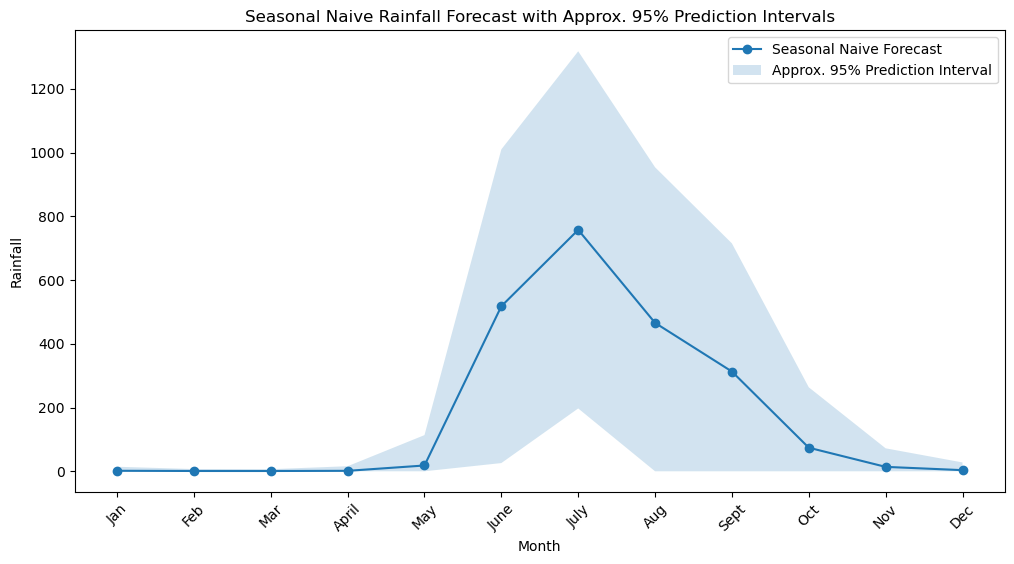

In [86]:
plt.figure(figsize=(12, 6))

plt.plot(
    final_forecast['Month_Name'],
    final_forecast['Forecasted_Rainfall'],
    marker='o',
    label='Seasonal Naive Forecast'
)

plt.fill_between(
    final_forecast['Month_Name'],
    final_forecast['Lower_95'],
    final_forecast['Upper_95'],
    alpha=0.2,
    label='Approx. 95% Prediction Interval'
)

plt.xlabel('Month')
plt.ylabel('Rainfall')
plt.title('Seasonal Naive Rainfall Forecast with Approx. 95% Prediction Intervals')
plt.legend()
plt.xticks(rotation=45)

plt.savefig(
    "graphs/final_rainfall_forecast_with_intervals.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## Final Forecasting Method

Based on the cross-validation and held-out test results, the seasonal-naive approach using the historical average rainfall for each calendar month is selected as the final forecasting method.

The seasonal-naive method provides performance comparable to, and slightly better than, the Random Forest models while being substantially simpler and more interpretable.

The final forecast therefore uses the historical rainfall average for each month to estimate rainfall for future months. The monthly averages are calculated using the complete historical dataset after model evaluation is complete.

In [87]:
final_monthly_average = rainfall_long.groupby('Month_Number')['Rainfall'].mean()

final_monthly_average

Month_Number
1       1.567235
2       0.929358
3       0.869231
4       1.428458
5      18.183632
6     517.854402
7     757.407412
8     465.600818
9     312.885747
10     73.983526
11     13.849462
12      3.556428
Name: Rainfall, dtype: float64

In [88]:
month_numbers = list(range(1, 13))

final_forecast = pd.DataFrame({
    'Month_Number': month_numbers,
    'Month_Name': [months[m - 1] for m in month_numbers],
    'Forecasted_Rainfall': [
        final_monthly_average[m] for m in month_numbers
    ]
})

final_forecast

,Month_Number,Month_Name,Forecasted_Rainfall
0,1,Jan,1.567235
1,2,Feb,0.929358
2,3,Mar,0.869231
3,4,April,1.428458
4,5,May,18.183632
5,6,June,517.854402
6,7,July,757.407412
7,8,Aug,465.600818
8,9,Sept,312.885747
9,10,Oct,73.983526


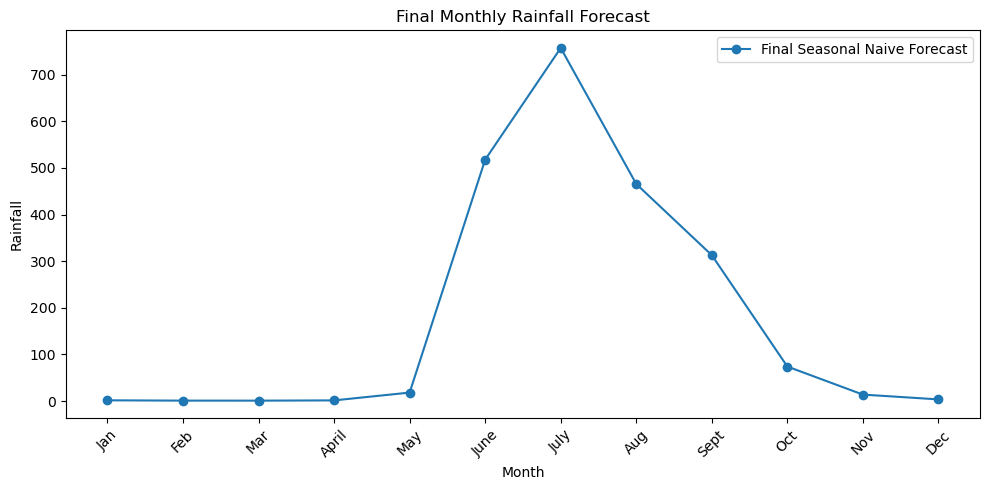

In [89]:
plt.figure(figsize=(10, 5))

plt.plot(
    final_forecast['Month_Name'],
    final_forecast['Forecasted_Rainfall'],
    marker='o',
    label='Final Seasonal Naive Forecast'
)

plt.xlabel('Month')
plt.ylabel('Rainfall')
plt.title('Final Monthly Rainfall Forecast')
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(
    "graphs/final_monthly_rainfall_forecast.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## Final Forecast Interpretation

The final forecast reflects the strong seasonal pattern observed in Mumbai rainfall. Rainfall is expected to remain very low during the dry months and increase substantially during the monsoon season, with July showing the highest expected rainfall.

These forecasts represent climatological expectations based on historical monthly averages rather than predictions of the exact rainfall for a particular future year. Therefore, they are useful for understanding expected seasonal rainfall patterns but cannot account for year-specific variations caused by external climatic conditions.

# Final Findings

The analysis produced several important findings:

1. Mumbai rainfall exhibits strong annual seasonality.
2. The same month in the previous year shows strong temporal dependence, as indicated by the lag-12 autocorrelation.
3. Lag and rolling features were useful for experimentation, but adding them did not improve the final forecasting performance.
4. Random Forest slightly outperformed XGBoost among the initial machine learning models.
5. The seasonal-naive monthly-average baseline achieved the strongest overall test performance.
6. The final forecast therefore primarily captures Mumbai's strong recurring monthly rainfall pattern.

# Limitations

This project has several limitations:

- The model uses historical rainfall data as its primary source of information and does not include external meteorological variables.
- The final model relies heavily on the recurring seasonal pattern and therefore may have limited ability to capture unusual year-to-year rainfall behavior.
- Extreme rainfall events are inherently difficult to predict accurately using historical monthly averages alone.
- The available dataset covers historical observations through 2021, limiting the amount of data available for learning longer-term climate variability.
- The future forecasts cannot be evaluated against actual future rainfall until those observations become available.
-  Because the final forecasting method uses historical monthly averages, it should be interpreted primarily as a seasonal forecasting approach rather than a model capable of explaining all short-term rainfall variation.

# Future Work

The forecasting system could be improved by incorporating additional information that may explain year-to-year and short-term rainfall variation.

Potential future improvements include:

- Incorporating temperature, humidity, wind, atmospheric pressure, and other meteorological variables.
- Incorporating larger-scale climate indicators such as ENSO-related variables.
- Testing models designed specifically for time-series forecasting.
- Exploring longer historical datasets where available.
- Evaluating probabilistic forecasting methods to provide prediction intervals rather than only point forecasts.
- Testing the model on newly observed rainfall data as future observations become available.
- Investigating whether separate models for different rainfall seasons or regimes could improve extreme-rainfall prediction.

## Conclusion

This project analyzed historical monthly rainfall data for Mumbai from 1901 to 2021 and developed and evaluated several forecasting approaches. The analysis identified a strong and consistent seasonal pattern, with rainfall concentrated primarily during the monsoon months. Autocorrelation analysis also showed temporal dependence in the rainfall series, motivating the creation of lag and rolling-window features.

Several machine learning models were evaluated, including Linear Regression, Random Forest, and XGBoost. Random Forest provided the strongest performance among the machine learning models, and hyperparameter tuning was performed using time-series cross-validation.

However, comparison with the Seasonal Naive baseline showed that the simpler climatological approach performed best overall. The Seasonal Naive model achieved an average cross-validation MAE of 77.35, RMSE of 149.80, and R² of 0.741 across five time-series folds. On the held-out test period, it achieved an MAE of 82.60, RMSE of 162.59, and R² of 0.749.

These results demonstrate that increasing model complexity did not provide a meaningful improvement for this dataset. The strong recurring seasonal pattern contains most of the predictive information that can be extracted from the available historical rainfall data.

The Seasonal Naive approach was therefore selected as the final forecasting method. It uses the historical average rainfall for each calendar month to generate forecasts for future months. Approximate prediction intervals are also provided to communicate the uncertainty associated with the forecasts.

Overall, this project demonstrates the importance of comparing complex machine learning models against simple forecasting baselines and selecting the approach based on validation performance rather than model complexity alone.

# Key Learnings

This project provided practical experience with:

- Time-series data preprocessing
- Wide-to-long data transformation
- Datetime indexing and chronological ordering
- Exploratory time-series analysis
- Seasonality and autocorrelation
- Lag and rolling-window feature engineering
- Time-aware train-test splitting
- Regression model comparison
- Random Forest and XGBoost
- Time-series cross-validation
- Hyperparameter tuning with GridSearchCV
- Baseline comparison
- Forecast generation
- Model evaluation using MAE, RMSE, and R²
- Understanding the trade-off between model complexity and predictive performance